# BHSM Blackhole Tracker: joint astrometry and parallax

This walkthrough audits the separately versioned 2023 known-system observations.
It uses **one BHSM Einstein/GHY optical potential counted once**. The joint
campaign retains failed noise models and does not promote their conditional
point masses to accepted black-hole measurements. The two archival pilot
follow-ups remain mass unresolved; this notebook is not a new target selection.

Install the matching wheel with `[astrometry]`. Set `BHSM_JOINT_SOURCEPACK` to
the unchanged `BHSM_OB110462_2023_SourcePack_v1.zip`, `BHSM_JOINT_RESULT` to a
saved v2 result, and optionally `BHSM_JOINT_PROFILE` to its saved profile. These
are external observation/analysis files, not fabricated resolved-image data.
Without them, cells explain what is missing and run no analysis. The complete
source pack includes attribution and third-party rights that override any
BHSM software restrictions. Source and citation: [BHSM Git](https://github.com/ncarberry64/Berger-Hopf-Standard-Model).

In [1]:
import os, json
from pathlib import Path
import numpy as np
from bhtracker.server import import_joint_sourcepack, joint_summary
from bhtracker.joint_mass_v2 import JointModel, fit_joint
from bhtracker.joint_report import validate_result
from bhtracker.report import export_analysis_bundle, replay_analysis

sourcepack = os.environ.get('BHSM_JOINT_SOURCEPACK')
dataset = import_joint_sourcepack(Path(sourcepack).read_bytes()) if sourcepack else None
if dataset is None:
    print('No measured input selected. Set BHSM_JOINT_SOURCEPACK to the reviewed source ZIP.')
else:
    print(json.dumps(joint_summary(dataset), indent=2))
    print('All original OGLE rows retained:', len(dataset.document['native_OGLE_all_rows']))

{
  "schema": "bhtracker.native_joint_mass.v1",
  "sha256": "d4fc2bfc9320c7eab8a33b93517f68f035a5d498ffb35ff548a638648143af96",
  "target": "OGLE-2011-BLG-0462/MOA-2011-BLG-191",
  "input_hash_algorithm": "bhtracker.canonical_numeric_json.v2",
  "photometry_rows": 12521,
  "astrometry_rows": 21,
  "time_coordinate": "JD_TDB",
  "metadata": {
    "ra_axis": "EAST_TANGENT_ALPHA_COS_DEC",
    "time_and_frame_provenance": {
      "OGLE": "Native full HJD. Underlying clock unspecified in author deposit; explicitly assumed HJD_UTC, inverted heliocentric light time at geocentre then converted TDB. Earth-surface light time <=0.0213sec omitted; +/-120sec clock sensitivity required.",
      "OGLE_clock_offset_seconds": 0.0,
      "HST": "Calendar dates mapped by program/filter/count/duration to82 complete MAST FLC primary headers. UTC default crosschecked to DATE/TIME-OBS; exposure midpoints derived. Original combined centroid/photometry weighting unknown; full-window sensitivity required.",
   

## Two measured scales, separate acceptance checks

$\theta_E^2=\kappa M\pi_{rel}$ and $\pi_E=\pi_{rel}/\theta_E$ give
$M=\theta_E/(\kappa\pi_E)$, while $\mu_{rel}=\theta_E/t_E$.
Duration alone supplies no mass. Absolute distance, absolute lens motion,
horizon and nongeometric core state remain unavailable in this relative frame.

Loading a recorded state verifies predictions and derived parameters with the
exact scientific source; it does not rerun optimization or establish adequate
noise. `RUN_NEW_FIT` is false by default. Setting it true runs a new conditional
16-start analysis, separate from the frozen campaign and its validation record.

In [2]:
RUN_NEW_FIT = False
saved = os.environ.get('BHSM_JOINT_RESULT')
result = json.loads(Path(saved).read_text(encoding='utf-8-sig')) if saved else None
if RUN_NEW_FIT:
    if dataset is None:
        raise ValueError('Import the reviewed observations before a new fit.')
    result = fit_joint(dataset, starts=16, max_nfev=600, gp=True,
                       noise_model='native_marginal_ou')
if result is None:
    print('No saved result selected; no mass or benchmark outcome is displayed.')
else:
    verified, model, replay = validate_result(result)
    if dataset is not None and verified.sha256 != dataset.sha256:
        raise ValueError('Saved result uses a different input version or selection.')
    print(replay)
    print('Recorded solver quantity only:', result['parameters']['mass_msun'])
    print('Acceptance:', result['mass_status'])
    print('Forward replay is not noise, mass or black-hole acceptance.')

{'schema': 'bhtracker.joint_replay.v2', 'passed': True, 'checks': {'objective_deviance': True, 'photometric_predictions_magnitude': True, 'astrometric_predictions_NE_mas': True}, 'input_sha256': 'd4fc2bfc9320c7eab8a33b93517f68f035a5d498ffb35ff548a638648143af96', 'scientific_source_sha256': '6eaf050481fc23aebf4b929e49fdab57e324ee80eb08e1547b69f056269eeaaa', 'max_photometric_difference_mag': 0.0, 'max_astrometric_difference_mas': 2.930988785010413e-14, 'same_physical_parameters': True, 'same_native_residuals': True, 'same_recorded_diagnostic_gates': True, 'method': 'FORWARD_STATE_REPLAY; optimization and scientific acceptance are separate'}
Recorded solver quantity only: 7.103285982270498
Acceptance: PROFILE_AND_SYSTEMATICS_REQUIRED
Forward replay is not noise, mass or black-hole acceptance.


In [3]:
if result is not None:
    print(json.dumps({
        'numerical_convergence': result['numerical_convergence'],
        'noise_and_structure_diagnostics': result['diagnostics'],
        'model_options': result['model_options'],
        'fit_configuration': result.get('fit_configuration'),
        'analysis_contract': result.get('analysis_contract'),
        'nonlinear_active_bounds': result['nonlinear_active_bounds'],
        'linear_active_bounds': result['linear_active_bounds'],
        'unavailable': result['unavailable'],
        'BHSM': result['bhsm_interpretation']}, indent=2))
    print('Every start retained:', len(result['all_starts']))

{
  "numerical_convergence": {
    "converged_starts": 16,
    "attempted_starts": 16,
    "best_objective_deviance": 12067.237171323228,
    "computational_time_origin_jd_tdb": 2455765.0,
    "optimization_constant_offset": 37446.653419424874,
    "profiled_nonlinear_rank": 13,
    "nonlinear_parameter_count": 13,
    "linear_parameter_count": 8
  },
  "noise_and_structure_diagnostics": {
    "astrometry_chi2": 32.38750744003493,
    "astrometry_dof_conservative": 29,
    "astrometry_chi2_tail_probability": 0.30312419784821387,
    "photometry_innovation_chi2": 12598.172831458007,
    "photometry_dof_approximate": 12508,
    "photometry_chi2_tail_probability_approximate": 0.2833328909143844,
    "GP_noise_inference_requires_simulation_calibration": true,
    "OGLE_sorted_innovation_lag1": 0.019803615074037117,
    "photometry_chi2_two_sided_probability_approximate": 0.5666657818287688,
    "astrometry_chi2_two_sided_probability_approximate": 0.6062483956964277
  },
  "model_options": 

## Native observations and residuals

Every OGLE row in the declared selection is plotted. The angular graph shows
both tangent-plane residuals with native marginal error bars. The likelihood
may hypothesize correlation; these bars do not imply that a full covariance
was supplied. Original HJD and exposure-window provenance stay in the input.

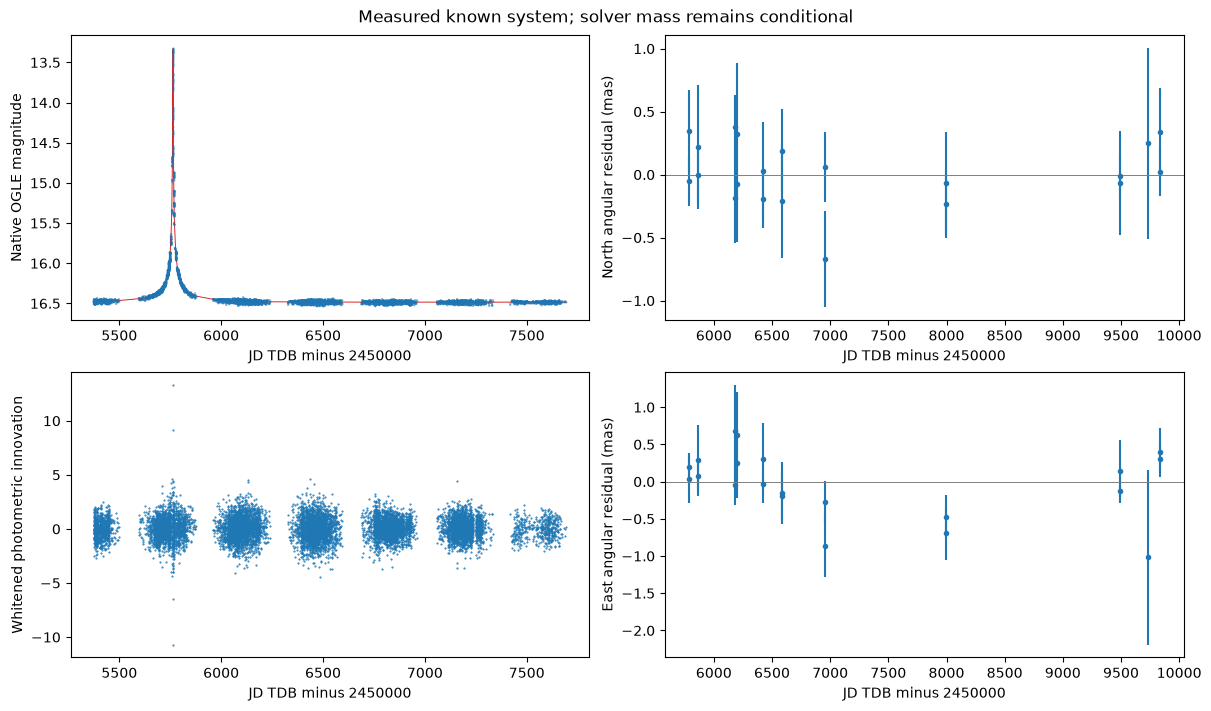

In [4]:
if result is not None:
    import matplotlib.pyplot as plt
    take = np.array([row['instrument'] == 'OGLE' for row in model.pr])
    prediction = np.asarray(result['photometric_predictions_magnitude'])
    fig, ax = plt.subplots(2, 2, figsize=(12, 7), layout='constrained')
    order = np.flatnonzero(take)[np.argsort(model.tp[take], kind='stable')]
    ax[0, 0].errorbar(model.tp[take]-2450000, model.yp[take], yerr=model.sp[take], fmt='.', ms=1, alpha=.4)
    ax[0, 0].plot(model.tp[order]-2450000, prediction[order], color='tab:red', lw=.7)
    ax[0, 0].invert_yaxis()
    ax[0, 0].set(ylabel='Native OGLE magnitude')
    ax[1, 0].plot(model.tp[take]-2450000, np.asarray(result['whitened_photometric_residuals'])[take], '.', ms=1)
    ax[1, 0].set(ylabel='Whitened photometric innovation')
    epochs = model.average(model.ta[:, None])[:, 0]
    for axis, label in enumerate(['North', 'East']):
        sigma = np.array([[r['north_error_mas'], r['east_error_mas']] for r in model.ar])[:, axis]
        ax[axis, 1].errorbar(epochs-2450000, np.asarray(result['astrometric_residuals_NE_mas'])[:, axis], yerr=sigma, fmt='.')
        ax[axis, 1].set(ylabel=label+' angular residual (mas)')
        ax[axis, 1].axhline(0, color='.5', lw=.7)
    for a in ax.flat:
        a.set(xlabel='JD TDB minus 2450000')
    fig.suptitle('Measured known system; solver mass remains conditional')
    plt.show()

## Profile, export and replay

Only eligible profile rows may bracket a local likelihood support crossing.
Unresolved rows interrupt a curve; finite grid endpoints are not confidence
limits. Noise, predictive and systematic gates remain separate. The frozen
campaign's inadequate fits do not become accepted masses because a numerical
profile is finite. Profiles are saved as separate audit files.

Profile rows: 31
Statuses: ['ADMITTED_LOCAL_PROFILE', 'BOUNDARY_LIMITED']


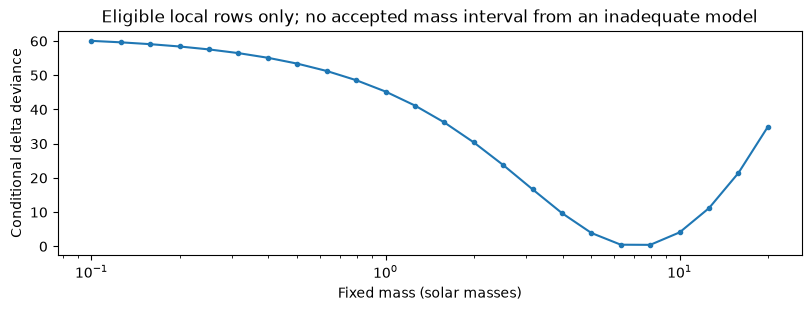

{'schema': 'bhtracker.joint_replay.v2', 'passed': True, 'checks': {'objective_deviance': True, 'photometric_predictions_magnitude': True, 'astrometric_predictions_NE_mas': True}, 'input_sha256': 'd4fc2bfc9320c7eab8a33b93517f68f035a5d498ffb35ff548a638648143af96', 'scientific_source_sha256': '6eaf050481fc23aebf4b929e49fdab57e324ee80eb08e1547b69f056269eeaaa', 'max_photometric_difference_mag': 0.0, 'max_astrometric_difference_mas': 2.930988785010413e-14, 'same_physical_parameters': True, 'same_native_residuals': True, 'same_recorded_diagnostic_gates': True, 'method': 'FORWARD_STATE_REPLAY; optimization and scientific acceptance are separate'}
Numerical replay only; retain independent acceptance and failed-model records.


In [5]:
profile_path = os.environ.get('BHSM_JOINT_PROFILE')
if profile_path and result is not None:
    profile = json.loads(Path(profile_path).read_text(encoding='utf-8-sig'))
    print('Profile rows:', len(profile['rows']))
    print('Statuses:', sorted({row['status'] for row in profile['rows']}))
    masses = [row['mass_msun'] for row in profile['rows']]
    support = [row['delta_deviance'] if row.get('interval_eligible') else np.nan for row in profile['rows']]
    fig, axis = plt.subplots(figsize=(8, 3), layout='constrained')
    axis.semilogx(masses, support, '.-')
    axis.set(xlabel='Fixed mass (solar masses)', ylabel='Conditional delta deviance',
             title='Eligible local rows only; no accepted mass interval from an inadequate model')
    plt.show()
else:
    print('No matching profile selected; no mass interval is invented.')
if result is not None:
    run = Path('user_runs/notebook_joint')
    run.mkdir(parents=True, exist_ok=True)
    bundle = run / 'joint_analysis.zip'
    bundle.write_bytes(export_analysis_bundle(result))
    check = replay_analysis(bundle, run / 'replayed')
    assert check['passed'] and check['same_physical_parameters']
    print(check)
    print('Numerical replay only; retain independent acceptance and failed-model records.')

The known-system experiment tests this particular data reduction and
likelihood. It does not establish performance over all known black holes,
unknown events or instruments. Discovery requires adequate new observations,
validated angular and parallax scales, darkness/alternative-lens constraints,
and catalog/literature checks. Failed alternatives remain part of the result.